# 02 · Performance ratio and long-term degradation

Using the cleaned data from notebook 01, this notebook estimates how fast the array is losing output.

The questions are:
1. What is the temperature-corrected performance ratio (PR), and how does it change over 13 years?
2. What is the degradation rate (%/year), with an honest confidence interval?
3. How much of that number depends on our own assumptions and on the irradiance sensor?

In [1]:
import json, sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src import performance as perf

FIG = ROOT / "figures"; RES = ROOT / "results"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
clean = pd.read_parquet(ROOT / "data/system4_clean.parquet")
solar = pd.read_parquet(ROOT / "data/solar.parquet")

P_STC = 1000.0     # W, 5 x 200 W Sanyo HIP-200BA3
GAMMA = -0.0030    # 1/degC, typical power temperature coefficient for HIT modules

## 1. Annual energy

In [2]:
ac = clean.ac_power.where(solar.elevation > 0).clip(lower=0)
annual = (ac.resample("YS").sum() / 60 / 1000).to_frame("AC energy (kWh)")
annual.index = annual.index.year
annual.round(0)

,AC energy (kWh)
2010,862.0
2011,1613.0
2012,1561.0
2013,1505.0
2014,1427.0
2015,1424.0
2016,1505.0
2017,34.0
2018,1158.0
2019,1186.0


Raw annual energy cannot measure degradation. It moves with weather, with gaps in the data and with
outages (2017). Energy has to be normalised by the sunlight the array actually received.

## 2. Temperature-corrected performance ratio

For every good daylight minute (sun above 10°, POA ≥ 200 W/m², all sensors passed QC):

$$P_{expected} = P_{STC}\cdot\frac{G_{POA}}{1000}\cdot\left[1+\gamma\,(T_{mod}-25)\right]$$

The daily PR is $\sum P_{AC} / \sum P_{expected}$. Correcting for temperature removes most of the
summer–winter swing, because hot modules produce less. Days still far from their neighbours (snow,
partial outages) are removed with a rolling-median filter.

3383 days with enough good data, 248 removed as outliers


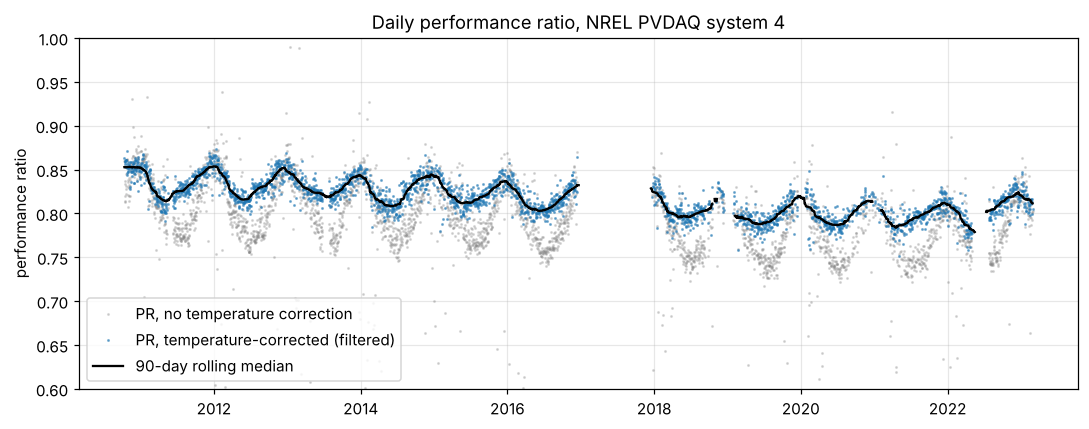

In [3]:
daily = perf.daily_pr(clean, solar.elevation, P_STC, GAMMA)
pr = perf.remove_outliers(daily.pr)
print(f"{len(daily)} days with enough good data, {len(daily) - len(pr)} removed as outliers")

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(daily.pr_uncorrected, ".", ms=2, alpha=0.25, color="grey", label="PR, no temperature correction")
ax.plot(pr, ".", ms=2, alpha=0.5, label="PR, temperature-corrected (filtered)")
ax.plot(pr.asfreq("D").rolling(90, center=True, min_periods=30).median(), color="k", lw=1.5, label="90-day rolling median")
ax.set_ylim(0.6, 1.0); ax.set_ylabel("performance ratio"); ax.legend(loc="lower left")
ax.set_title("Daily performance ratio, NREL PVDAQ system 4")
fig.tight_layout(); fig.savefig(FIG / "05_daily_pr.png")

In [4]:
seasonal = pd.DataFrame({
    "uncorrected": daily.pr_uncorrected.groupby(daily.index.month).median(),
    "temperature-corrected": pr.groupby(pr.index.month).median(),
})
print("Seasonal swing (max-min of monthly medians):", (seasonal.max() - seasonal.min()).round(3).to_dict())
seasonal.round(3).T

Seasonal swing (max-min of monthly medians): {'uncorrected': 0.07699999958276749, 'temperature-corrected': 0.035999998450279236}


,1,2,3,4,5,6,7,8,9,10,11,12
uncorrected,0.834,0.810,0.796,0.785,0.780,0.761,0.759,0.766,0.776,0.802,0.821,0.836
temperature-corrected,0.839,0.823,0.811,0.805,0.804,0.805,0.803,0.811,0.818,0.828,0.833,0.839


## 3. Year-on-year (YoY) degradation

This is the method used by NREL's RdTools. Each day's PR is compared with the PR exactly one year later. The
median of thousands of these one-year changes is the degradation rate. Each pair shares the same
season and roughly the same sun angles, so seasonal effects cancel. The method also tolerates gaps
such as the 2017 outage. The confidence interval comes from bootstrapping the yearly changes.

Degradation rate: -0.30 %/year (95% CI -0.38 to -0.21), from 2,009 day pairs


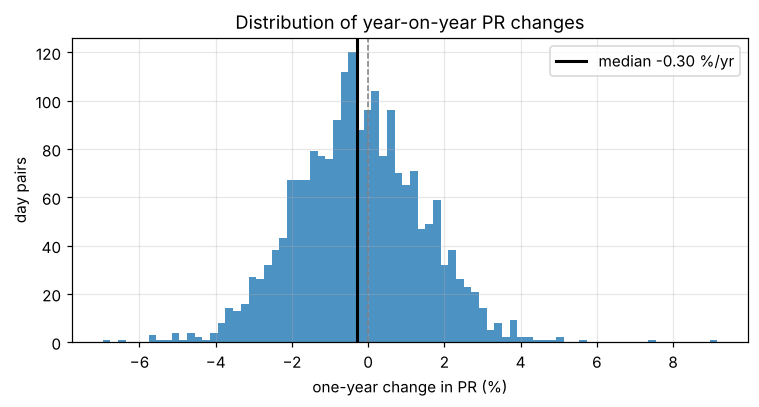

In [5]:
yoy = perf.yoy_degradation(pr)
print(f"Degradation rate: {yoy['rate']:.2f} %/year "
      f"(95% CI {yoy['ci_low']:.2f} to {yoy['ci_high']:.2f}), from {yoy['n_pairs']:,} day pairs")

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.hist(yoy["rates"].clip(-10, 10), bins=80, color="tab:blue", alpha=0.8)
ax.axvline(yoy["rate"], color="k", lw=2, label=f"median {yoy['rate']:.2f} %/yr")
ax.axvline(0, color="grey", lw=1, ls="--")
ax.set_xlabel("one-year change in PR (%)"); ax.set_ylabel("day pairs"); ax.legend()
ax.set_title("Distribution of year-on-year PR changes")
fig.tight_layout(); fig.savefig(FIG / "06_yoy_histogram.png")

### Validation against RdTools

The same filtered daily PR goes into NREL's open-source `rdtools.degradation_year_on_year`. This checks
the from-scratch implementation.

In [6]:
import rdtools
rd_rate, rd_ci, _ = rdtools.degradation_year_on_year(pr.asfreq("D"), confidence_level=95)
print(f"RdTools: {rd_rate:.2f} %/year (95% CI {rd_ci[0]:.2f} to {rd_ci[1]:.2f})")
print(f"This repo: {yoy['rate']:.2f} %/year (95% CI {yoy['ci_low']:.2f} to {yoy['ci_high']:.2f})")

RdTools: -0.28 %/year (95% CI -0.37 to -0.19)
This repo: -0.30 %/year (95% CI -0.38 to -0.21)


## 4. How sensitive is the answer?

### 4a. Temperature coefficient
The datasheet coefficient is an assumption, so the analysis is repeated with ±0.05 %/°C.

In [7]:
rows = []
for g in (-0.0025, -0.0030, -0.0035):
    d = perf.daily_pr(clean, solar.elevation, P_STC, g)
    r = perf.yoy_degradation(perf.remove_outliers(d.pr))
    rows.append({"gamma (%/°C)": g * 100, "rate (%/yr)": r["rate"], "CI low": r["ci_low"], "CI high": r["ci_high"]})
r = perf.yoy_degradation(perf.remove_outliers(daily.pr_uncorrected))
rows.append({"gamma (%/°C)": "no correction", "rate (%/yr)": r["rate"], "CI low": r["ci_low"], "CI high": r["ci_high"]})
lin = perf.linear_trend(pr)
rows.append({"gamma (%/°C)": "-0.30, linear fit on monthly medians", "rate (%/yr)": lin["rate"], "CI low": np.nan, "CI high": np.nan})
sens = pd.DataFrame(rows)
sens.round(2)

,gamma (%/°C),rate (%/yr),CI low,CI high
0,-0.25,-0.25,-0.33,-0.17
1,-0.3,-0.30,-0.38,-0.21
2,-0.35,-0.26,-0.36,-0.15
3,no correction,-0.36,-0.48,-0.22
4,"-0.30, linear fit on monthly medians",-0.41,NaN,NaN


### 4b. Is the irradiance sensor itself drifting?

The PR divides by the POA pyranometer reading. If the pyranometer slowly reads low (soiling of its dome,
ageing), the PR looks better than it is and degradation is **under**-estimated. To check this, the
analysis is repeated on **clear days only**, using the modelled clear-sky irradiance instead of the
sensor. The model does not age. It does not know the day's aerosols, so it is noisier, which is why
these estimates use monthly medians.

In [8]:
cdays = pd.to_datetime(pd.read_csv(RES / "clear_days.csv").date)
m = pd.Index(clean.index.normalize()).isin(cdays) & (solar.elevation > 10).values
d = clean.loc[m, ["ac_power", "poa", "t_mod"]].assign(cs=solar.poa_clearsky[m]).dropna()
d["p_cs"] = perf.expected_power(d.cs, d.t_mod, P_STC, GAMMA)
g = d.groupby(d.index.normalize())
clear = pd.DataFrame({"sensor / clear-sky model": g.poa.sum() / g.cs.sum(),
                      "PR vs clear-sky model": g.ac_power.sum() / g.p_cs.sum(),
                      "n": g.size()})
clear = clear[clear.n > 300]

def monthly_yoy(s, n_boot=2000, seed=0):
    mm = s.resample("MS").median().dropna()
    later = mm.copy(); later.index = later.index - pd.DateOffset(years=1)
    p = pd.concat([mm.rename("a"), later.rename("b")], axis=1, join="inner")
    rates = (p.b / p.a - 1) * 100
    boots = np.median(np.random.default_rng(seed).choice(rates.values, (n_boot, len(rates))), axis=1)
    return rates.median(), *np.percentile(boots, [2.5, 97.5]), len(rates)

out = {c: monthly_yoy(clear[c]) for c in ["sensor / clear-sky model", "PR vs clear-sky model"]}
out["PR vs sensor (main result)"] = (yoy["rate"], yoy["ci_low"], yoy["ci_high"], yoy["n_pairs"])
check = pd.DataFrame(out, index=["rate (%/yr)", "CI low", "CI high", "pairs"]).T
check.round(2)

,rate (%/yr),CI low,CI high,pairs
sensor / clear-sky model,-0.33,-0.76,0.24,91.0
PR vs clear-sky model,-0.62,-1.02,0.16,91.0
PR vs sensor (main result),-0.30,-0.38,-0.21,2009.0


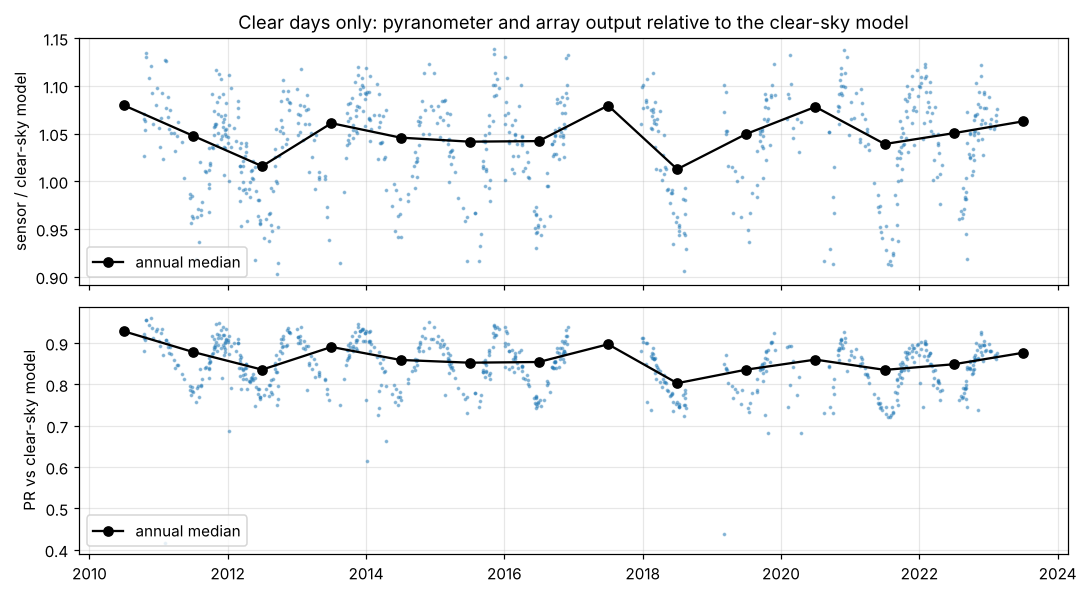

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True)
for ax, col in zip(axes, ["sensor / clear-sky model", "PR vs clear-sky model"]):
    ax.plot(clear[col], ".", ms=3, alpha=0.4)
    ax.plot(clear[col].resample("YS").median().shift(182, freq="D"), "o-", color="k", label="annual median")
    ax.set_ylabel(col); ax.legend(loc="lower left")
axes[0].set_title("Clear days only: pyranometer and array output relative to the clear-sky model")
fig.tight_layout(); fig.savefig(FIG / "07_clear_sky_check.png")

### 4c. Is the decline steady?

The daily PR plot suggests it is not. PR falls steadily up to 2016, sits lower after the 2017 outage,
and then rises again in 2022–2023. The YoY method is run separately on each stretch. (The 2010 and 2017 annual medians below cover only
a few winter weeks, when PR is seasonally highest, so they are not comparable with full years.)

In [10]:
segments = {"2010–2016 (before outage)": ("2010", "2016"),
            "2018–2021 (after outage)": ("2018", "2021"),
            "2018–2023 (incl. last 14 months)": ("2018", "2023"),
            "full record": ("2010", "2023")}
seg = pd.DataFrame({k: perf.yoy_degradation(pr[a:b]) for k, (a, b) in segments.items()}).T
seg = seg[["rate", "ci_low", "ci_high", "n_pairs"]].astype(float).round(2)
seg.to_csv(RES / "degradation_by_period.csv")
annual_pr = pr.groupby(pr.index.year).median().round(3).rename("median PR")
display(seg, annual_pr.to_frame().T)

,rate,ci_low,ci_high,n_pairs
2010–2016 (before outage),-0.39,-0.49,-0.31,1332.0
2018–2021 (after outage),-0.37,-0.49,-0.22,505.0
2018–2023 (incl. last 14 months),-0.03,-0.22,0.14,677.0
full record,-0.30,-0.38,-0.21,2009.0


,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
median PR,0.853,0.832,0.831,0.829,0.824,0.821,0.813,0.831,0.802,0.795,0.795,0.799,0.807,0.815


## 5. Results

In [11]:
results = pd.DataFrame({
    "method": ["YoY on sensor-based PR (main)", "RdTools YoY (validation)",
               "Linear fit on monthly PR", "YoY on clear-sky PR (sensor-independent)",
               "Pyranometer vs clear-sky model"],
    "rate (%/yr)": [yoy["rate"], rd_rate, lin["rate"], check.iloc[1, 0], check.iloc[0, 0]],
    "CI low": [yoy["ci_low"], rd_ci[0], np.nan, check.iloc[1, 1], check.iloc[0, 1]],
    "CI high": [yoy["ci_high"], rd_ci[1], np.nan, check.iloc[1, 2], check.iloc[0, 2]],
}).round(2)
results.to_csv(RES / "degradation_results.csv", index=False)
sens.round(3).to_csv(RES / "temperature_coefficient_sensitivity.csv", index=False)
daily.assign(kept=daily.index.isin(pr.index)).to_csv(RES / "daily_pr.csv")
results

,method,rate (%/yr),CI low,CI high
0,YoY on sensor-based PR (main),-0.30,-0.38,-0.21
1,RdTools YoY (validation),-0.28,-0.37,-0.19
2,Linear fit on monthly PR,-0.41,NaN,NaN
3,YoY on clear-sky PR (sensor-independent),-0.62,-1.02,0.16
4,Pyranometer vs clear-sky model,-0.33,-0.76,0.24


### Takeaways

* **Main estimate:** over the full record the temperature-corrected PR falls by **0.30 %/year
  (95 % CI 0.21–0.38)**. The from-scratch year-on-year implementation and NREL's RdTools (0.28 %/yr)
  agree closely.
* **The decline is not uniform.** Within each stable period it runs at about **0.4 %/yr**: 2010–2016
  and 2018–2021 give nearly the same rate. Two features pull the full-record number down. There is a
  step loss across the 2017 outage, and PR recovers in 2022–2023. The data cannot say whether the
  recovery comes from the array (for example a component change during maintenance) or from the
  irradiance sensor. A single headline rate hides this, which is why segment analysis is worth doing.
  For comparison, large field studies report a median of ~0.5 %/yr for crystalline-silicon systems.
* **Temperature correction halves the seasonal swing** in PR (from 0.077 to 0.036). The trend barely
  depends on the exact coefficient: ±0.05 %/°C moves the rate by at most 0.05 %/yr. A simple linear fit
  on monthly medians gives 0.41 %/yr. It is less robust to the long gaps, which is why YoY is the
  main method.
* **The irradiance sensor is the main open question.** On clear days the pyranometer trends about
  0.3 %/yr lower than the clear-sky model, and the sensor-independent clear-sky PR falls about
  0.6 %/yr. Both point to the sensor-based rate *understating* degradation. With only ~90 monthly pairs,
  however, both intervals include zero. The honest statement is **about 0.3 %/yr, possibly up to
  ~0.6 %/yr if the pyranometer drifted**. Checking the sensor's calibration records would settle it.
* **Without QC this analysis would be wrong.** The 2017 outage alone would look like a near-total
  failure, and the −7,999 codes in the temperature channels would corrupt the temperature
  correction.